# Data vs sims
Processed data (run `analysis_tools/process_pff.ipynb` first) against processed sim_telarray productions (run
`process_sims.ipynb` on each first), with the same selection: Hillas parameters, profiles, and events with mean scaled width
and length. The data are almost all cosmic rays, so the protons are the main comparison.

Everything is set in **Selection** below: pick the data's analysis config and a simulation config per production, then
override any of the telescopes, nights or selection there. The histograms and profiles are made by the functions in
**Plotting**.

Only parameters that don't depend on the camera's orientation are compared (no `x_c`, `y_c`, `phi`): the data's cameras
are fixed to the sky (+x east, +y south, after the postflip rotation), the simulation's to the alt-az mount. `distance`
and `alpha` are from the camera center in both (for the data, before `pointing_corrections`, which only move `x_c`,
`y_c`). Some things this doesn't match:
* each production is simulated at one pointing, while the data spans altitudes (see the runs' pointings below)
* the data's `size` is divided by `rel_tel_efficiency`; the simulated telescopes are identical
* the night sky background and the cleaning thresholds' pedvars differ from night to night

# Imports

In [45]:
import json
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
from sklearn.model_selection import GroupKFold

from heap import diagnostics as dg
from heap import events as ev
from heap import process_simulation as ps
from heap.config import load_analysis_config, local_analysis, local_simulation
from heap.process_dataset import slugify
from heap.sources import SOURCES
from heap.reconstruction import core_distances, reconstruct_cores, reconstruct_directions, tilted_frame, tilted_positions
from simulation_tools.run_simulation import load_config

# Selection

In [46]:
CONFIG = local_analysis() # the analysis config configs/local.yaml names, or any other, e.g. Path("../../configs/analysis/<name>.yaml")
cfg = load_analysis_config(CONFIG)

RAW_DATA_DIR = cfg["paths"]["raw_data_dir"]
OUTPUT_DIR = cfg["paths"]["output_dir"]
SOURCE = cfg["source"]["name"]

# one simulation config per production: configs/local.yaml's, or any other, e.g. Path("~/simulations/<name>.yaml")
SIM_CONFIGS = {
    "proton": local_simulation("proton"),
    "gamma": local_simulation("gamma"),
}
# the spectral index each production is weighted to (dN/dE ~ E^index), None = as simulated; e.g. -2.7 for cosmic-ray protons
SPECTRAL_INDEX = {"proton": None, "gamma": None}

# the simulated telescope standing in for each data telescope; sim_telarray ids follow the TELESCOPE lines of
# configs/corsika.example.inp
SIM_TELESCOPES = {"Heli": "T1", "Winter": "T2", "Fern": "T3", "Gattini": "T4"}

# override any of these, e.g. TELESCOPES = ["Fern", "Winter"] or IMAGE_CUTS = {"width": ("value", 0.3)}
DATES = None # None = every night in OUTPUT_DIR with SOURCE; the config's are cfg["source"]["dates"]
TELESCOPES = ["Heli", "Winter", "Fern"] # the ones processed in OUTPUT_DIR; the config's are cfg["cuts"]["telescopes"]
REFERENCE = cfg["events"]["reference"]
MIN_TEL = cfg["cuts"]["min_tel"]
MIN_NPIX = cfg["cuts"]["min_npix"]
# the config's are cfg["cuts"]["image_cuts"]; "nsigma" thresholds are per sample, so they cut the data and the sims in
# different places: use "value" cuts here
IMAGE_CUTS = {}

# event building
COINC_WINDOW = cfg["events"]["coinc_window"]
ROTATE_POSTFLIP = cfg["events"]["rotate_postflip"]
REL_TEL_EFFICIENCY = cfg["events"]["rel_tel_efficiency"]
POINTING_CORRECTIONS = cfg["events"]["pointing_corrections"]
POINTING_OVERRIDES = cfg["source"]["pointing_overrides"]

# mean scaled width and length: LOOKUP_SAMPLE's width and length in bins of these two columns
LOOKUP_SAMPLE = "gamma"
LOOKUP_X, LOOKUP_Y = "log10_size", "impact_reco" # or LOOKUP_Y = "distance"
LOOKUP_X_BINS = np.arange(1.5, 5.01, 0.25)
LOOKUP_Y_BINS = np.arange(0, 501, 50) # m; e.g. np.arange(0, 5.01, 0.5) deg for distance

# plotting
COLORS = {"data": "k", "proton": "C3", "gamma": "C0"}

# Plotting

In [47]:
# column: (axis label, bin edges)
HILLAS_PARAMS = {
    "N_pix": ("N_pix", np.arange(0.5, 81.5, 2)),
    "log10_size": ("log10 size (ADC)", np.linspace(1, 6, 51)),
    "length": ("length (deg)", np.linspace(0, 2, 51)),
    "width": ("width (deg)", np.linspace(0, 1, 51)),
    "length_width": ("length / width", np.linspace(1, 10, 46)),
    "length_log10_size": ("length / log10 size (deg)", np.linspace(0, 1, 51)),
    "distance": ("distance (deg)", np.linspace(0, 7, 36)),
    "alpha": ("alpha (deg)", np.linspace(0, 90, 31)),
    "miss": ("miss (deg)", np.linspace(0, 3, 31)),
    "impact_reco": ("reconstructed impact (m)", np.linspace(0, 600, 41)),
}
EVENT_PARAMS = { # see event_parameters()
    "n_images": ("images per event", np.arange(0.5, 8.5)),
    "log10_total_size": ("log10 total size (ADC)", np.linspace(1, 6, 41)),
    "max_distance": ("max distance (deg)", np.linspace(0, 7, 36)),
    "MSCW": ("mean scaled width", np.linspace(-2, 5, 57)),
    "MSCL": ("mean scaled length", np.linspace(-2, 5, 57)),
}

def legend_and_title(fig, ax, n_panels, title):
    """the suptitle and ax's legend, shared below the suptitle if there are several panels"""
    if n_panels > 1:
        # constrained layout puts an outside legend over the suptitle, so the legend's title stands in for it
        handles, labels = ax.get_legend_handles_labels()
        fig.legend(handles, labels, loc="outside upper center", ncols=len(labels), fontsize=8, frameon=False,
                   title=title, title_fontsize="large")
    else:
        ax.legend(fontsize=8)
        fig.suptitle(title)

def plot_hists(samples, params, title, n_cols=4):
    """
    each sample's normalized, weighted histogram, one panel per column of params, and under each panel every
    simulated sample divided by the data
    """
    n_rows = int(np.ceil(len(params) / n_cols))
    fig, axs = plt.subplots(2*n_rows, n_cols, figsize=(4.2*n_cols, 4.6*n_rows), squeeze=False, layout="constrained",
                            gridspec_kw={"height_ratios": [3, 1]*n_rows})
    for ax in axs.flat:
        ax.axis("off")
    for i, (column, (label, bins)) in enumerate(params.items()):
        ax, ratio_ax = axs[2*(i // n_cols), i % n_cols], axs[2*(i // n_cols) + 1, i % n_cols]
        ax.axis("on")
        ratio_ax.axis("on")
        counts = {}
        for name, sample in samples.items():
            s = sample.dropna(subset=[column])
            counts[name], _, _ = ax.hist(s[column], bins, weights=s.weight, density=True, histtype="step",
                                         color=COLORS[name], label=f"{name} N={len(s)}")
        centers = (bins[1:] + bins[:-1]) / 2
        for name in samples:
            if name != "data":
                with np.errstate(divide="ignore", invalid="ignore"):
                    ratio_ax.plot(centers, counts[name] / counts["data"], ".", color=COLORS[name])
        ratio_ax.axhline(1, color="k", lw=0.8)
        ax.set(ylabel="normalized counts", xlim=(bins[0], bins[-1]))
        ax.tick_params(labelbottom=False)
        ratio_ax.set(xlabel=label, ylabel="/ data", xlim=(bins[0], bins[-1]), ylim=(0, 3))
    legend_and_title(fig, axs[0, 0], len(params), title)
    plt.show()

def plot_profiles(samples, profiles, title, n_cols=4, min_entries=10):
    """each sample's weighted mean of y in bins of x, with its error, one panel per (x, y, x bin edges) in profiles"""
    n_rows = int(np.ceil(len(profiles) / n_cols))
    fig, axs = plt.subplots(n_rows, n_cols, figsize=(4.2*n_cols, 3.6*n_rows), squeeze=False, layout="constrained")
    for ax, (x, y, bins) in zip(axs.flat, profiles):
        centers = (bins[1:] + bins[:-1]) / 2
        for name, sample in samples.items():
            s = sample.dropna(subset=[x, y])
            n, _ = np.histogram(s[x], bins)
            sw, _ = np.histogram(s[x], bins, weights=s.weight)
            with np.errstate(divide="ignore", invalid="ignore"):
                mean = np.histogram(s[x], bins, weights=s.weight * s[y])[0] / sw
                std = np.sqrt(np.clip(np.histogram(s[x], bins, weights=s.weight * s[y]**2)[0] / sw - mean**2, 0, None))
            ok = n >= min_entries
            ax.errorbar(centers[ok], mean[ok], yerr=std[ok] / np.sqrt(n[ok]), fmt="o-", ms=3, color=COLORS[name], label=name)
        ax.set(xlabel=x, ylabel=f"mean {y}")
    legend_and_title(fig, axs.flat[0], len(profiles), title)
    for ax in axs.flat[len(profiles):]:
        ax.axis("off")
    plt.show()

In [48]:
if DATES is None:
    products = dg.product_table(OUTPUT_DIR)
    DATES = sorted(products[products.Source == slugify(SOURCE, sep="_")].Date.unique())
missing = [name for name in TELESCOPES if name not in SIM_TELESCOPES]
if missing:
    raise ValueError(f"no simulated telescope for {missing}: add them to SIM_TELESCOPES")
sim_names = {SIM_TELESCOPES[name]: name for name in TELESCOPES} # sim_telarray id -> data telescope
print(f"{SOURCE}, nights {DATES}, telescopes {TELESCOPES} (simulated as {list(sim_names)})")
SELECTED = BASE_SELECTED = f"≥{MIN_TEL} images per event, ≥{MIN_NPIX} pixels per image" + (f", {IMAGE_CUTS}" if IMAGE_CUTS else "")
print(f"selected events: {SELECTED} (and the additional cuts below)")

Crab, nights ['20260114', '20260115', '20260117', '20260118', '20260119', '20260120', '20260121', '20260223', '20260917', '20260918', '20260922', '20261015', '20261016', '20261018'], telescopes ['Heli', 'Winter', 'Fern'] (simulated as ['T1', 'T2', 'T3'])
selected events: ≥2 images per event, ≥3 pixels per image (and the additional cuts below)


# Events
The data's images of `TELESCOPES` matched into array events within `COINC_WINDOW` (`heap.events.build_array_events()`),
as in `analysis_tools/explore_events.ipynb`, and each production's images of the telescopes standing in for them
(`SIM_TELESCOPES`, renamed after them) matched by `Run` and `EventID` (`heap.process_simulation.load_events()`), with
their shower's spectral weight. Then the same selection for all, the selection (`heap.events.apply_cuts()`): at least `MIN_TEL` images per event, `MIN_NPIX` pixels per image, and any `IMAGE_CUTS`. Each selected image's reconstructed impact distance (`impact_reco`) comes from the same core reconstruction for all
(`heap.reconstruction`), with the data's telescope positions from its analysis config and the simulated ones from their
production.

In [49]:
dfs = []
pointings = {} # each run's pointing
for date in DATES:
    night, night_pointings = ev.build_array_events(
        OUTPUT_DIR, RAW_DATA_DIR / date, date, SOURCE, TELESCOPES, REFERENCE, window=COINC_WINDOW,
        rotate_postflip=ROTATE_POSTFLIP, rel_tel_efficiency=REL_TEL_EFFICIENCY, pointing_corrections=POINTING_CORRECTIONS,
        pointing_overrides=POINTING_OVERRIDES,
    )
    pointings |= night_pointings
    if night is None or len(night) == 0:
        print(f"{date}: no {SOURCE} events")
        continue
    night["Event"] += dfs[-1].Event.max() + 1 if dfs else 0 # unique across nights
    dfs.append(night)
images = {"data": pd.concat(dfs, ignore_index=True).assign(weight=1.0)}
print(f"data: {images['data'].Event.nunique()} events ({len(images['data'])} images), {len(pointings)} runs")

obs_Palomar.start_2026-01-14T02:52:30Z.runtype_obs-test.pffd: no mount position at its start and no pointing_overrides, leaving it out
obs_Palomar.start_2026-01-14T06:00:03Z.runtype_obs-test.pffd: no mount position at its start and no pointing_overrides, leaving it out
20260114: no Crab events
obs_Palomar.start_2026-01-15T02:26:39Z.runtype_obs-test.pffd: no mount position at its start and no pointing_overrides, leaving it out
obs_Palomar.start_2026-01-15T05:54:39Z.runtype_obs-test.pffd: no mount position at its start and no pointing_overrides, leaving it out
20260115: no Crab events
obs_Palomar.start_2026-01-17T06:11:13Z.runtype_obs-test.pffd: no mount position at its start and no pointing_overrides, leaving it out
20260117: no Crab events
obs_Palomar.start_2026-01-18T06:47:35Z.runtype_obs-test.pffd, 06:48:41-08:39:41 UTC: timing reference Winter; Heli 2807, Winter 2499, Fern 3273 images
Winter-Heli, run 06:47:35, 06:48:41-08:39:41 UTC timing offset: RMS=  0.00358 s, std= 0.00214 s
Win

/home/korzoun/Software/miniconda3/envs/panoseti/lib/python3.11/site-packages/numpy/_core/fromnumeric.py:3860: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
/home/korzoun/Software/miniconda3/envs/panoseti/lib/python3.11/site-packages/numpy/_core/_methods.py:145: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)
/home/korzoun/Software/miniconda3/envs/panoseti/lib/python3.11/site-packages/numpy/_core/fromnumeric.py:3860: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
/home/korzoun/Software/miniconda3/envs/panoseti/lib/python3.11/site-packages/numpy/_core/_methods.py:145: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)
/home/korzoun/Software/miniconda3/envs/panoseti/lib/python3.11/site-packages/numpy/_core/fromnumeric.py:3860: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
/h

obs_Palomar.start_2026-01-20T02:24:17Z.runtype_obs-test.pffd, 02:25:25-05:30:25 UTC: timing reference Winter; Heli 5141, Winter 4267, Fern 5759 images
Winter-Heli, run 02:24:17, 02:25:25-05:30:25 UTC timing offset: RMS=  0.00317 s, std= 0.0021 s
Winter-Heli, run 02:24:17, 02:25:25-05:30:25 UTC corrected offset: RMS=  0.0 s, std= 0.0 s
Winter-Fern, run 02:24:17, 02:25:25-05:30:25 UTC timing offset: RMS=  0.00374 s, std= 0.00311 s
Winter-Fern, run 02:24:17, 02:25:25-05:30:25 UTC corrected offset: RMS=  1e-05 s, std= 1e-05 s
Heli-Winter within 0.001s: 1156/5139 Heli events (22.5%) and 1156/4267 Winter events (27.1%) coincident, 1157 pairs
Heli-Fern within 0.001s: 1787/5139 Heli events (34.8%) and 1789/5753 Fern events (31.1%) coincident, 1790 pairs
Winter-Fern within 0.001s: 1431/4267 Winter events (33.5%) and 1433/5753 Fern events (24.9%) coincident, 1435 pairs
2685 events; dropped 4 ambiguous groups (a telescope matched more than one image)

obs_Palomar.start_2026-01-20T05:33:29Z.runtyp

/home/korzoun/Software/miniconda3/envs/panoseti/lib/python3.11/site-packages/numpy/_core/fromnumeric.py:3860: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
/home/korzoun/Software/miniconda3/envs/panoseti/lib/python3.11/site-packages/numpy/_core/_methods.py:145: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)
/home/korzoun/Software/miniconda3/envs/panoseti/lib/python3.11/site-packages/numpy/_core/fromnumeric.py:3860: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
/home/korzoun/Software/miniconda3/envs/panoseti/lib/python3.11/site-packages/numpy/_core/_methods.py:145: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


obs_Palomar.start_2026-02-23T04:57:32Z.runtype_obs-test.pffd, 04:58:25-06:45:25 UTC: timing reference Fern (no Winter images); Heli 2855, Fern 3473 images
Fern-Heli, run 04:57:32, 04:58:25-06:45:25 UTC timing offset: RMS=  0.00357 s, std= 0.00158 s
Fern-Heli, run 04:57:32, 04:58:25-06:45:25 UTC corrected offset: RMS=  0.0 s, std= 0.0 s
Heli-Fern within 0.001s: 628/2854 Heli events (22.0%) and 628/3473 Fern events (18.1%) coincident, 628 pairs
628 events; dropped 0 ambiguous groups (a telescope matched more than one image)

obs_Palomar.start_2026-09-17T09:50:18Z.runtype_eng-dual.pffd, 09:51:23-10:51:23 UTC: timing reference Winter; Heli 3357, Winter 3972, Fern 3076 images
Winter-Heli, run 09:50:18, 09:51:23-10:51:23 UTC timing offset: RMS=  7e-05 s, std= 6e-05 s
Winter-Heli, run 09:50:18, 09:51:23-10:51:23 UTC corrected offset: RMS=  0.0 s, std= 0.0 s
Winter-Fern, run 09:50:18, 09:51:23-10:51:23 UTC timing offset: RMS=  7e-05 s, std= 6e-05 s
Winter-Fern, run 09:50:18, 09:51:23-10:51:23 

/home/korzoun/Software/miniconda3/envs/panoseti/lib/python3.11/site-packages/numpy/_core/fromnumeric.py:3860: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
/home/korzoun/Software/miniconda3/envs/panoseti/lib/python3.11/site-packages/numpy/_core/_methods.py:145: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)
/home/korzoun/Software/miniconda3/envs/panoseti/lib/python3.11/site-packages/numpy/_core/fromnumeric.py:3860: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
/home/korzoun/Software/miniconda3/envs/panoseti/lib/python3.11/site-packages/numpy/_core/_methods.py:145: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


10236 events; dropped 190 ambiguous groups (a telescope matched more than one image)

obs_Palomar.start_2026-10-15T09:29:58Z.runtype_ph.pffd, 11:54:50-11:55:50 UTC: timing reference Fern (no Winter images); Heli 15, Fern 6 images
Fern-Heli, run 09:29:58, 11:54:50-11:55:50 UTC timing offset: RMS=  4e-05 s, std= 0.0 s
Fern-Heli, run 09:29:58, 11:54:50-11:55:50 UTC corrected offset: RMS=  0.0 s, std= 0.0 s
Heli-Fern within 0.001s: 3/15 Heli events (20.0%) and 3/6 Fern events (50.0%) coincident, 3 pairs
3 events; dropped 0 ambiguous groups (a telescope matched more than one image)

obs_Palomar.start_2026-10-15T12:02:30Z.runtype_ph.pffd, 12:03:20-12:28:20 UTC: timing reference Winter; Heli 7601, Winter 19248, Fern 7838 images
Winter-Heli, run 12:02:30, 12:03:20-12:28:20 UTC timing offset: RMS=  0.00021 s, std= 0.00018 s
Winter-Heli, run 12:02:30, 12:03:20-12:28:20 UTC corrected offset: RMS=  4e-05 s, std= 3e-05 s
Winter-Fern, run 12:02:30, 12:03:20-12:28:20 UTC timing offset: RMS=  0.00063 

/home/korzoun/Software/miniconda3/envs/panoseti/lib/python3.11/site-packages/numpy/_core/fromnumeric.py:3860: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
/home/korzoun/Software/miniconda3/envs/panoseti/lib/python3.11/site-packages/numpy/_core/_methods.py:145: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)
/home/korzoun/Software/miniconda3/envs/panoseti/lib/python3.11/site-packages/numpy/_core/fromnumeric.py:3860: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
/home/korzoun/Software/miniconda3/envs/panoseti/lib/python3.11/site-packages/numpy/_core/_methods.py:145: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


11005 events; dropped 163 ambiguous groups (a telescope matched more than one image)

obs_Palomar.start_2026-10-18T11:52:39Z.runtype_ph.pffd, 11:53:29-12:30:29 UTC: timing reference Winter; Heli 7493, Winter 16304, Fern 7084 images
Winter-Heli, run 11:52:39, 11:53:29-12:30:29 UTC timing offset: RMS=  0.0004 s, std= 0.00036 s
Winter-Heli, run 11:52:39, 11:53:29-12:30:29 UTC corrected offset: RMS=  0.0 s, std= 0.0 s
Winter-Fern, run 11:52:39, 11:53:29-12:30:29 UTC timing offset: RMS=  0.00084 s, std= 0.00063 s
Winter-Fern, run 11:52:39, 11:53:29-12:30:29 UTC corrected offset: RMS=  1e-05 s, std= 1e-05 s
Heli-Winter within 0.001s: 1040/7493 Heli events (13.9%) and 1053/16304 Winter events (6.5%) coincident, 1060 pairs
Heli-Fern within 0.001s: 1378/7493 Heli events (18.4%) and 1379/7084 Fern events (19.5%) coincident, 1388 pairs
Winter-Fern within 0.001s: 1311/16304 Winter events (8.0%) and 1303/7084 Fern events (18.4%) coincident, 1323 pairs
2347 events; dropped 48 ambiguous groups (a tel

In [50]:
sim_cfgs = {label: load_config(path) for label, path in SIM_CONFIGS.items()}
runs, showers = {}, {}
for label, sim_cfg in sim_cfgs.items():
    runs[label], imgs, showers[label] = ps.load_production(sim_cfg, list(sim_names))
    header = runs[label].iloc[0]
    # each shower's weight from the simulated power law to SPECTRAL_INDEX, mean 1
    weight = showers[label].energy ** ((SPECTRAL_INDEX[label] or header.spectral_index) - header.spectral_index)
    showers[label]["weight"] = weight / weight.mean()
    imgs = imgs.merge(showers[label][["Event", "weight"]], on="Event")
    imgs["Telescope"] = imgs.Telescope.map(sim_names)
    images[label] = imgs
    print(f"{label}: {sim_cfg['production']['name']} ({sim_cfg['sim_telarray']['tag']}), {imgs.Event.nunique()} events "
          f"({len(imgs)} images), {header.energy_range[0]:g}-{header.energy_range[1]:g} TeV, index {header.spectral_index:.2g} "
          f"weighted to {SPECTRAL_INDEX[label]}, pointing alt {runs[label].alt.mean():.2f}, az {runs[label].az.mean():.2f} deg")

proton: proton_diffuse (v2), 116412 events (136951 images), 6-2000 TeV, index -2.7 weighted to None, pointing alt 70.00, az 191.03 deg
gamma: gamma_pointlike (v2), 49281 events (60871 images), 3-1000 TeV, index -2.7 weighted to None, pointing alt 70.00, az 191.03 deg


In [51]:
# every sample should be cleaned the same way
CLEANING = ["image_threshold", "border_threshold", "keep_brightest_island"]
settings = {
    f"data {date} {name}": json.loads(path.read_text())
    for date in DATES for name in TELESCOPES if (path := OUTPUT_DIR / date / name / "processing.json").exists()
}
settings |= {
    label: json.loads((ps.processed_path(sim_cfg) / f"{sim_cfg['production']['name']}_processing.json").read_text())
    for label, sim_cfg in sim_cfgs.items()
}
settings = pd.DataFrame(settings).T[CLEANING]
if len(settings.drop_duplicates()) > 1:
    warnings.warn("the samples were cleaned differently, see the table below: set the productions' pipeline sections to "
                  "the data's and rerun process_sims.ipynb on them")
settings.reset_index(names="sample").groupby(CLEANING)["sample"].agg(", ".join).to_frame("samples")

,,,samples
image_threshold,border_threshold,keep_brightest_island,
4.0,2.0,True,"data 20260114 Heli, data 20260114 Winter, data..."


In [52]:
# the data runs' pointings, against the productions' (above)
pd.DataFrame({run: {"ra": p.ra.deg, "dec": p.dec.deg} for run, p in pointings.items()}).T

,ra,dec
obs_Palomar.start_2026-01-18T06:47:35Z.runtype_obs-test.pffd,83.654089,21.999197
obs_Palomar.start_2026-01-19T04:10:14Z.runtype_obs-test.pffd,83.643565,22.015281
obs_Palomar.start_2026-01-19T05:35:23Z.runtype_obs-test.pffd,83.640965,22.016565
obs_Palomar.start_2026-01-20T02:24:17Z.runtype_obs-test.pffd,83.646030,22.016211
obs_Palomar.start_2026-01-20T05:33:29Z.runtype_obs-test.pffd,83.643495,22.016538
obs_Palomar.start_2026-01-21T02:21:18Z.runtype_obs-test.pffd,83.635405,22.016446
obs_Palomar.start_2026-01-21T05:33:11Z.runtype_obs-test.pffd,83.643875,22.016832
obs_Palomar.start_2026-02-23T04:57:32Z.runtype_obs-test.pffd,83.652136,21.963070
obs_Palomar.start_2026-09-17T09:50:18Z.runtype_eng-dual.pffd,83.636480,22.516722
obs_Palomar.start_2026-09-17T11:08:55Z.runtype_eng-phonly.pffd,83.635385,22.493922


In [53]:
arrays = {}
for label, imgs in images.items():
    imgs["log10_size"] = np.log10(imgs["size"].where(imgs["size"] > 0))
    imgs["length_width"] = imgs.length / imgs.width
    imgs["length_log10_size"] = imgs.length / imgs.log10_size
    arrays[label] = ev.apply_cuts(imgs, min_tel=MIN_TEL, min_npix=MIN_NPIX, telescopes=TELESCOPES, cuts=IMAGE_CUTS)
    if label == "data":
        tel_pos, frame = cfg["telescope_positions"], ev.sky_frame(arrays[label], pointings, cfg["site"])
    else:
        header = runs[label].iloc[0]
        tel_pos = {sim_names[f"T{tel_id}"]: pos for tel_id, pos in zip(header.tel_id, header.tel_pos) if f"T{tel_id}" in sim_names}
        frame = tilted_frame(runs[label].alt.mean(), runs[label].az.mean())
    positions = tilted_positions(arrays[label], tel_pos, *frame)
    arrays[label]["impact_reco"] = core_distances(arrays[label], positions, reconstruct_cores(arrays[label], positions))
    print(f"{label}: {arrays[label].Event.nunique()} events ({len(arrays[label])} images) selected")

data: 69827 events (162076 images) selected
proton: 14958 events (32714 images) selected
gamma: 8272 events (18249 images) selected


## Additional cuts
Image cuts on the selected images, after the selection above; each event then needs `MIN_TEL` images left. Cores and
`impact_reco` stay as reconstructed in the selection. Everything below uses the images passing them; rerun the cell above
before loosening them.

In [66]:
# pandas queries on the images' columns, e.g. "length / log10_size > 0.2", "width < 0.3", "Telescope != 'Heli'"; [] = none
ADDITIONAL_CUTS = ["length / log10_size > 0.22"]

for label, array in arrays.items():
    for cut in ADDITIONAL_CUTS:
        array = array.query(cut)
    arrays[label] = array[array.groupby("Event").Event.transform("size") >= MIN_TEL]
    print(f"{label}: {arrays[label].Event.nunique()} events ({len(arrays[label])} images) pass")
SELECTED = ", ".join([BASE_SELECTED, *ADDITIONAL_CUTS])
print(f"selected events: {SELECTED}")

data: 6747 events (15285 images) pass
proton: 11 events (22 images) pass
gamma: 2 events (4 images) pass
selected events: ≥2 images per event, ≥3 pixels per image, length / log10_size > 0.22


In [67]:
# fraction of selected events per telescope combination (sims unweighted)
pd.DataFrame({
    label: array.groupby("Event").Telescope.agg(lambda t: " + ".join(sorted(t))).value_counts(normalize=True)
    for label, array in arrays.items()
}).fillna(0).sort_values("data", ascending=False).style.format("{:.1%}")

,data,proton,gamma
Telescope,,,
Fern + Heli,34.7%,54.5%,50.0%
Fern + Heli + Winter,26.5%,0.0%,0.0%
Fern + Winter,21.8%,18.2%,50.0%
Heli + Winter,16.9%,27.3%,0.0%


# Hillas parameters
Normalized histograms of every image of the selected events, the sims weighted by their shower's spectral weight; below each,
every simulated sample divided by the data.

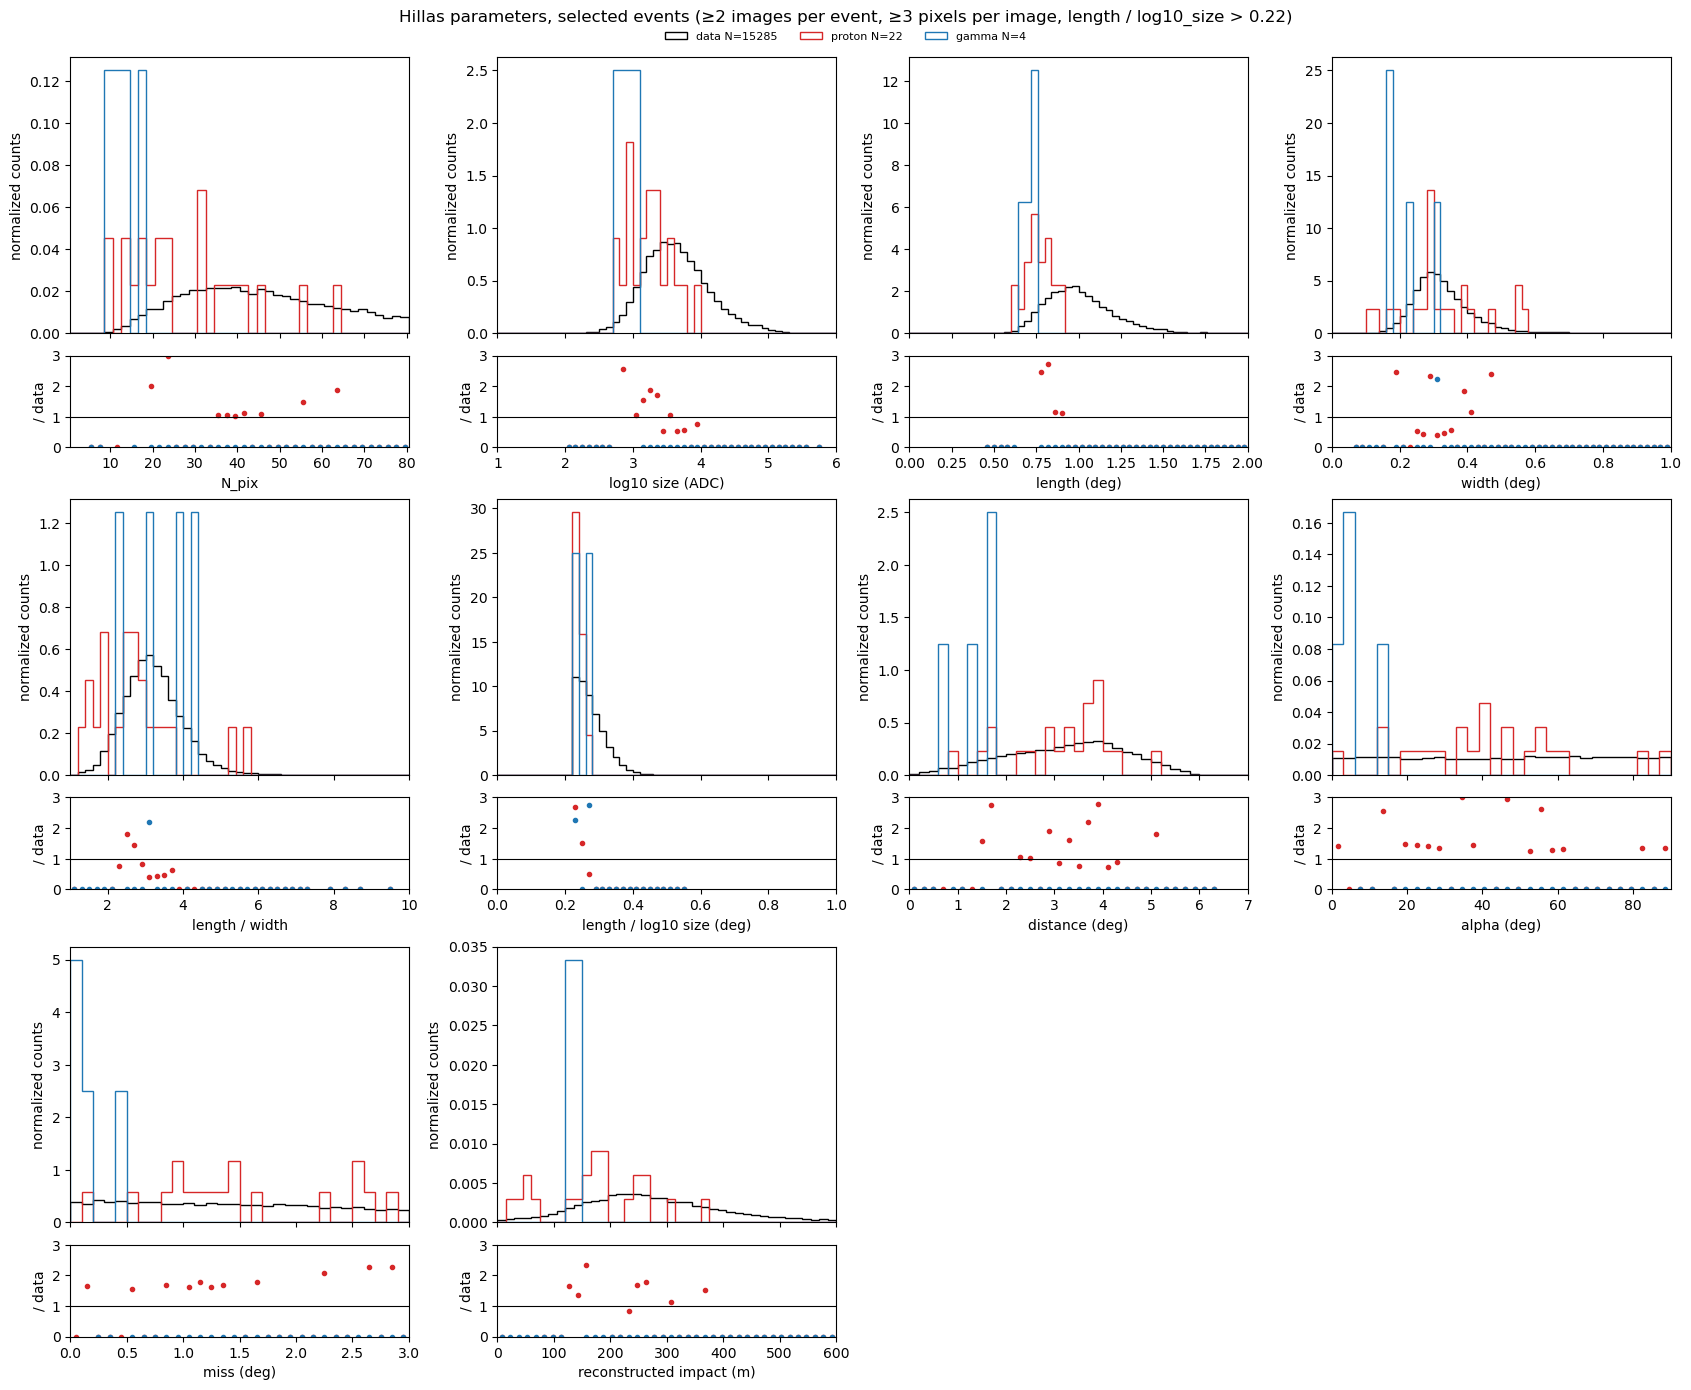

In [68]:
plot_hists(arrays, HILLAS_PARAMS, f"Hillas parameters, selected events ({SELECTED})")

In [69]:
pd.concat({label: array[["N_pix", "size", "length", "width", "length_width", "distance", "alpha", "impact_reco"]].describe() for label, array in arrays.items()}, axis=1)

data                                                           \
              N_pix           size        length         width  length_width   
count  15285.000000   15285.000000  15285.000000  15285.000000  15285.000000   
mean      61.598430    9063.261072      1.005858      0.328554      3.210695   
std       47.331546   17819.067499      0.200547      0.097896      0.789121   
min        6.000000     106.734452      0.460040      0.078421      1.122023   
25%       34.000000    2029.609029      0.862945      0.268688      2.679696   
50%       50.000000    4022.639783      0.981035      0.312094      3.146103   
75%       73.000000    8593.715251      1.118615      0.368300      3.651121   
max      978.000000  560949.280159      2.259812      1.569383     10.370931   

                                                    proton               ...  \
           distance         alpha   impact_reco      N_pix         size  ...   
count  15285.000000  15285.000000  15283.000000  22.000000    22.000000  ...   
mean       3.227685     45.390561    322.312042  28.090909  2329.524988  ...   
std        1.228060     26.097961    675.838417  14.644710  2166.693637  ...   
min        0.044715      0.016527      0.095936   9.000000   503.292899  ...   
25%        2.318668     22.561391    191.425087  17.250000   897.717314  ...   
50%        3.334409     46.141110    265.862718  23.000000  1711.382621  ...   
75%        4.146118     68.051285    362.782478  37.250000  2591.199928  ...   
max        6.276225     89.995847  39434.073028  63.000000  9616.097126  ...   

                                  gamma                                   \
           alpha impact_reco      N_pix         size    length     width   
count  22.000000   22.000000   4.000000     4.000000  4.000000  4.000000   
mean   40.797003  174.000008  13.000000   738.339501  0.709832  0.219661   
std    21.323330   91.889675   3.559026   218.878573  0.038008  0.068847   
min     2.453706   25.718928  10.000000   504.692478  0.659158  0.165075   
25%    25.708016  130.451274  10.750000   605.599579  0.691398  0.168718   
50%    39.677458  175.829348  12.000000   717.260925  0.719881  0.200486   
75%    53.975496  238.339544  14.250000   850.000846  0.738315  0.251429   
max    87.042079  369.564699  18.000000  1014.143676  0.740408  0.312600   

                                                     
      length_width  distance      alpha impact_reco  
count     4.000000  4.000000   4.000000    4.000000  
mean      3.447231  1.381255   6.135199  424.378544  
std       0.936875  0.459693   6.171141  339.771502  
min       2.246150  0.751369   0.515231  127.953587  
25%       2.955997  1.189291   3.449468  138.056932  
50%       3.592852  1.498335   4.541756  391.408491  
75%       4.084086  1.690299   7.227487  677.730103  
max       4.357073  1.776978  14.942053  786.743606  

[8 rows x 24 columns]

## Per telescope

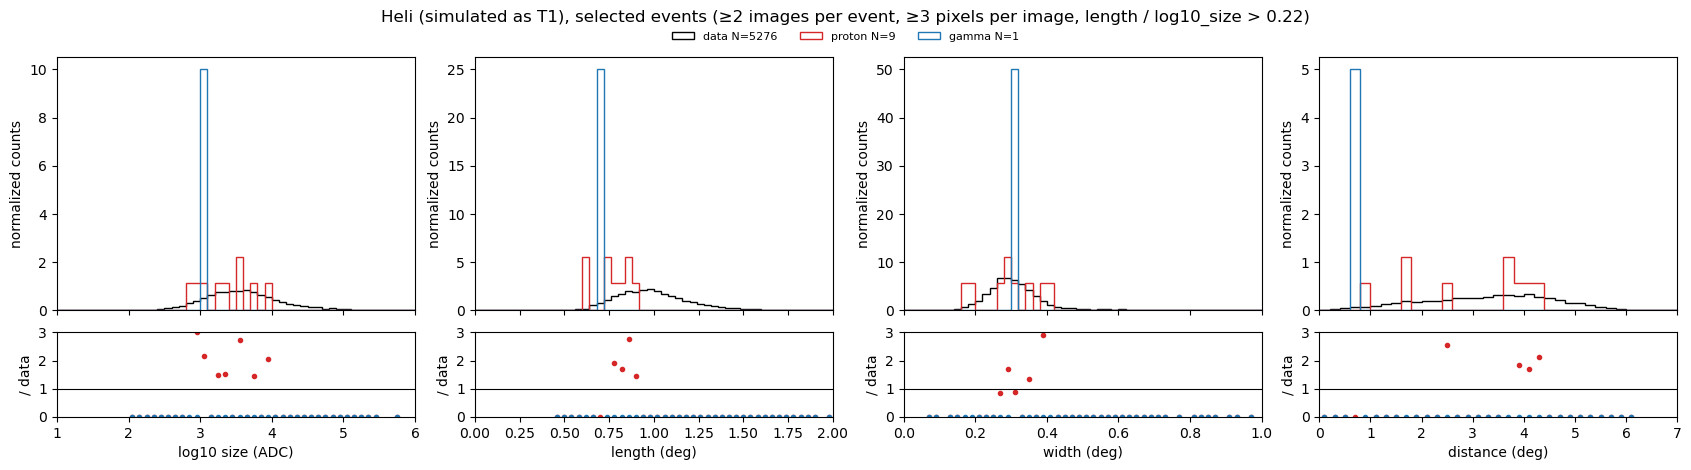

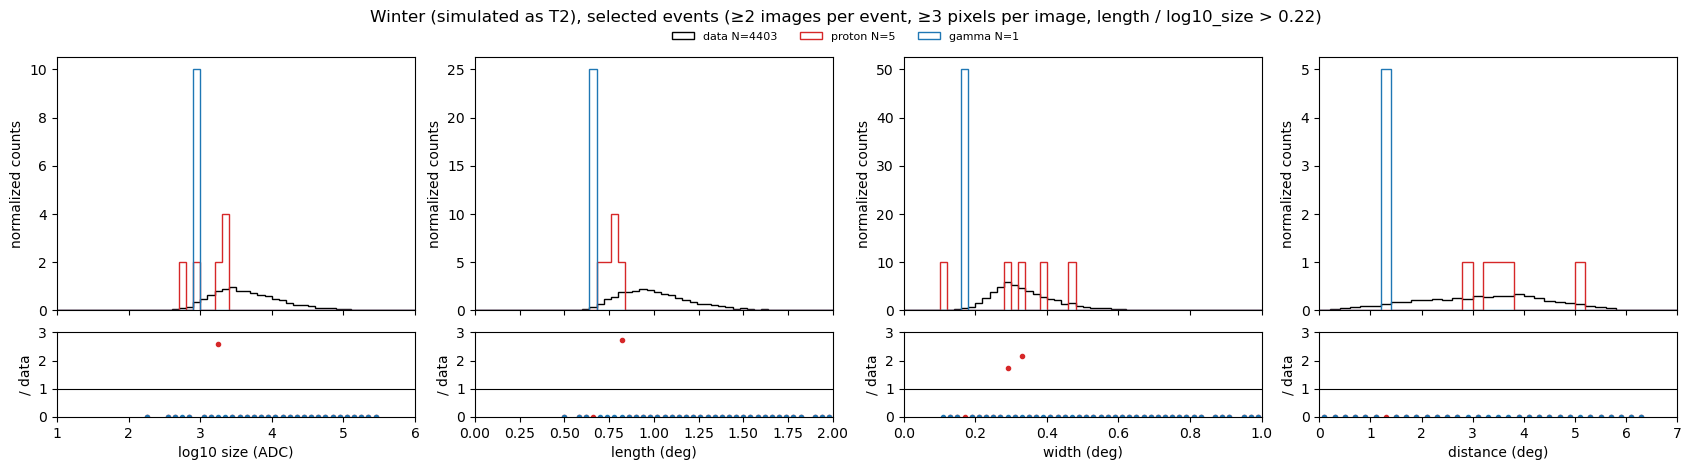

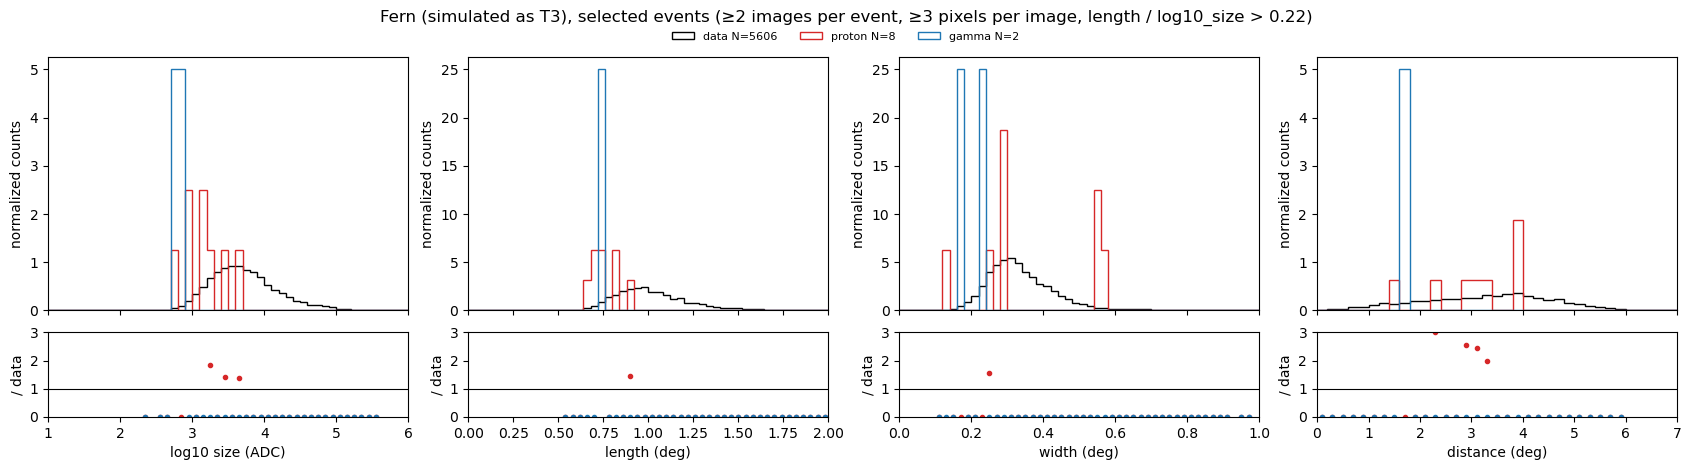

In [70]:
for name in TELESCOPES:
    plot_hists(
        {label: array[array.Telescope == name] for label, array in arrays.items()},
        {column: HILLAS_PARAMS[column] for column in ["log10_size", "length", "width", "distance"]},
        f"{name} (simulated as {SIM_TELESCOPES[name]}), selected events ({SELECTED})",
    )

## Profiles
Mean of one parameter in bins of another for the selected events, with its error.

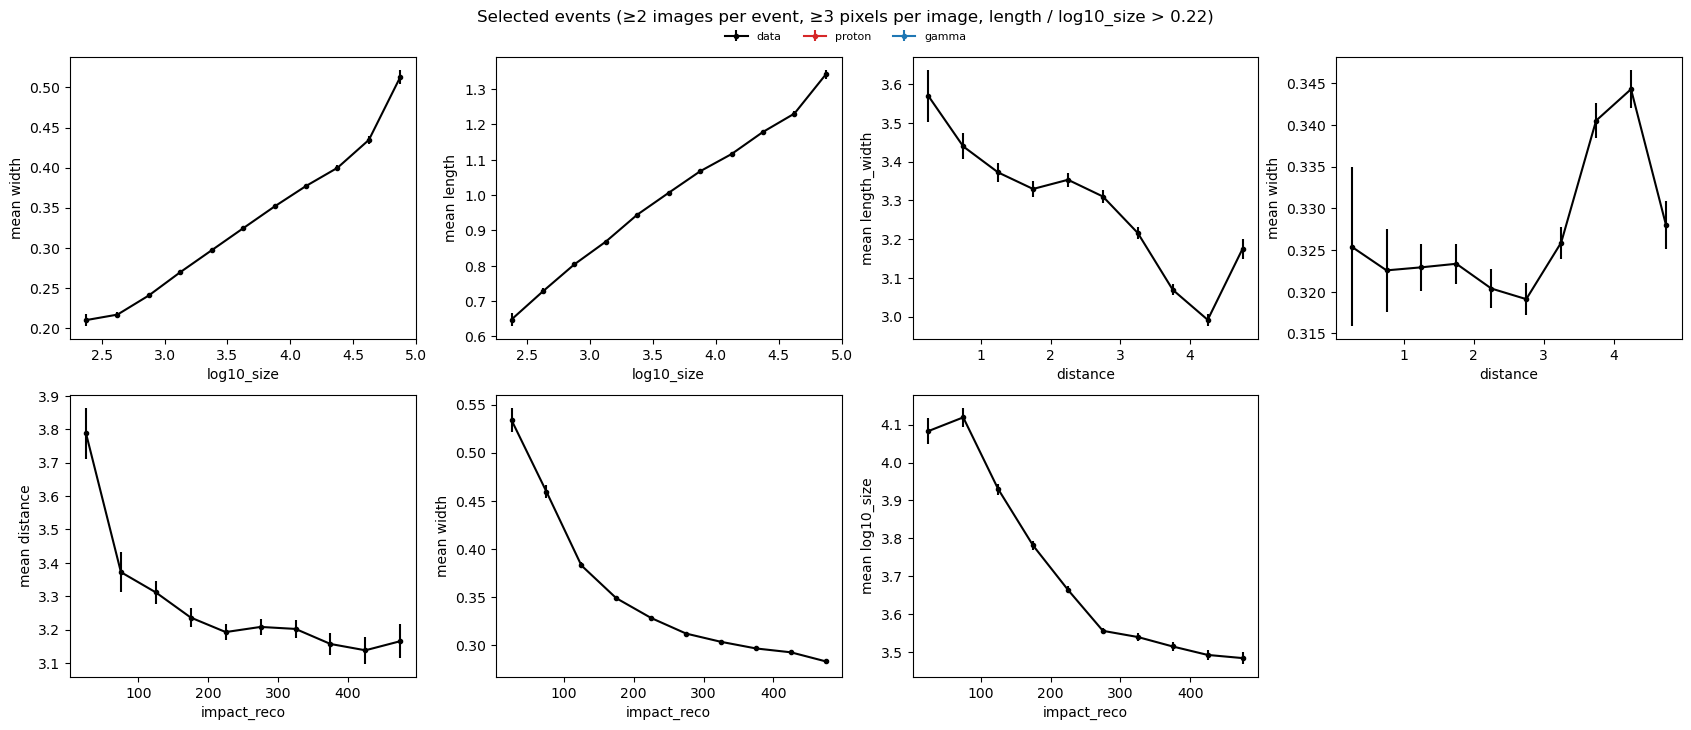

In [71]:
PROFILES = [ # (x, y, x bin edges): mean y in bins of x
    ("log10_size", "width", np.linspace(1.5, 5, 15)),
    ("log10_size", "length", np.linspace(1.5, 5, 15)),
    ("distance", "length_width", np.linspace(0, 5, 11)),
    ("distance", "width", np.linspace(0, 5, 11)),
    ("impact_reco", "distance", np.linspace(0, 500, 11)),
    ("impact_reco", "width", np.linspace(0, 500, 11)),
    ("impact_reco", "log10_size", np.linspace(0, 500, 11)),
]
plot_profiles(arrays, PROFILES, f"Selected events ({SELECTED})")

# Mean scaled width and length
Lookup tables of `LOOKUP_SAMPLE`'s weighted median and sigma (its 84% - 16% range, twice a Gaussian's sigma) of width and length per bin of `LOOKUP_X` and `LOOKUP_Y`, interpolated between bin centers and applied to every sample. `MSCWT` and `MSCWTSigma` are each image's expected width and its sigma from the tables, and its `scaled_width` is (width - `MSCWT`) / `MSCWTSigma`. Each event's mean scaled width, `MSCW`, is the mean of its images' `scaled_width` weighted by (`MSCWT` / `MSCWTSigma`)²; the same for length (`MSCLT`, `MSCLTSigma`, `scaled_length`, `MSCL`). Images outside the tables (or in bins with too few images) are left out. `LOOKUP_SAMPLE`'s values are out-of-fold: each quarter of its events uses tables of the other three quarters, so none is scaled by tables it helped make; the other samples use the tables of all of it, which are the ones shown.

In [72]:
def lookup_bins(images):
    """each image's (LOOKUP_X, LOOKUP_Y) bin, -1 outside LOOKUP_X_BINS, LOOKUP_Y_BINS"""
    return pd.DataFrame({
        "xi": pd.cut(images[LOOKUP_X], LOOKUP_X_BINS, labels=False).fillna(-1).astype(int),
        "yi": pd.cut(images[LOOKUP_Y], LOOKUP_Y_BINS, labels=False).fillna(-1).astype(int),
    })

def lookup_table(images, column, min_images=10):
    """weighted median of column and sigma, its 84% - 16% range, per (LOOKUP_X, LOOKUP_Y) bin with at least min_images images"""
    images = pd.concat([images[[column, "weight"]], lookup_bins(images)], axis=1).dropna()
    images = images[(images.xi >= 0) & (images.yi >= 0)]
    def quantiles(group):
        group = group.sort_values(column)
        low, median, high = np.interp([0.16, 0.5, 0.84], group.weight.cumsum() / group.weight.sum(), group[column])
        return pd.Series({"median": median, "sigma": high - low, "n": len(group)})
    table = images.groupby(["xi", "yi"])[[column, "weight"]].apply(quantiles)
    return table[table.n >= min_images]

def interpolate_between(value1, center1, value2, center2, x):
    """linear interpolation between two bins; with one NaN, the other bin's value if x is closer to it, else NaN"""
    fraction1 = 1 - (x - center1) / (center2 - center1)
    both = fraction1 * value1 + (1 - fraction1) * value2
    both = np.where(np.isnan(value2) & (fraction1 > 0.5), value1, both)
    return np.where(np.isnan(value1) & (fraction1 < 0.5), value2, both)

def from_table(images, table, key):
    """each image's key of table, interpolated between bin centers, first in LOOKUP_Y and then LOOKUP_X; NaN outside it"""
    n_x, n_y = len(LOOKUP_X_BINS) - 1, len(LOOKUP_Y_BINS) - 1
    grid = np.pad(table[key].unstack().reindex(index=range(n_x), columns=range(n_y)).to_numpy(dtype=float), 1, constant_values=np.nan) # bin i is grid[i + 1]
    x_centers = (LOOKUP_X_BINS[1:] + LOOKUP_X_BINS[:-1]) / 2
    y_centers = (LOOKUP_Y_BINS[1:] + LOOKUP_Y_BINS[:-1]) / 2
    x_centers = np.r_[2*x_centers[0] - x_centers[1], x_centers, 2*x_centers[-1] - x_centers[-2]]
    y_centers = np.r_[2*y_centers[0] - y_centers[1], y_centers, 2*y_centers[-1] - y_centers[-2]]
    bins = lookup_bins(images)
    xi, yi = bins.xi.to_numpy(), bins.yi.to_numpy()
    x, y = images[LOOKUP_X].to_numpy(), images[LOOKUP_Y].to_numpy()
    inside = (xi >= 0) & (yi >= 0)
    # the bins below each image's center: bin - 1 if it is below its bin's center
    i = np.where(inside, xi + 1 - (x < x_centers[np.where(inside, xi + 1, 0)]), 0)
    j = np.where(inside, yi + 1 - (y < y_centers[np.where(inside, yi + 1, 0)]), 0)
    with np.errstate(divide="ignore", invalid="ignore"):
        in_y = [interpolate_between(grid[i + k, j], y_centers[j], grid[i + k, j + 1], y_centers[j + 1], y) for k in (0, 1)]
        values = interpolate_between(in_y[0], x_centers[i], in_y[1], x_centers[i + 1], x)
    # no interpolation in the last bins
    last = inside & ((xi == n_x - 1) | (yi == n_y - 1))
    values[last] = grid[xi[last] + 1, yi[last] + 1]
    values[~inside] = np.nan
    return values

def out_of_fold_expected(column):
    """{label: (each image's expected column and sigma)}, LOOKUP_SAMPLE's from tables of its other events, the others' from tables of all of it"""
    lookup_images = arrays[LOOKUP_SAMPLE]
    expected, sigma = np.full(len(lookup_images), np.nan), np.full(len(lookup_images), np.nan)
    for fit, apply in GroupKFold(4).split(lookup_images, groups=lookup_images.Event):
        table = lookup_table(lookup_images.iloc[fit], column)
        expected[apply], sigma[apply] = from_table(lookup_images.iloc[apply], table, "median"), from_table(lookup_images.iloc[apply], table, "sigma")
    results = {label: (from_table(array, tables[column], "median"), from_table(array, tables[column], "sigma")) for label, array in arrays.items() if label != LOOKUP_SAMPLE}
    results[LOOKUP_SAMPLE] = expected, sigma
    return results

def scale(array, column, expected, sigma):
    """(array's column - expected) / sigma, and each image's weight (expected / sigma)^2; NaN without a positive expected and sigma"""
    good = (expected > 0) & (sigma > 0)
    expected, sigma = np.where(good, expected, np.nan), np.where(good, sigma, np.nan)
    return (array[column].to_numpy() - expected) / sigma, (expected / sigma)**2

def mean_scaled(array, scaled, weight):
    """per event, the mean of its images' scaled values weighted by weight"""
    return (array[scaled] * array[weight]).groupby(array.Event).sum() / array[weight].groupby(array.Event).sum()

def event_parameters(array):
    """
    one row per event: n_images, log10_total_size (of its images' summed size), max_distance (of its farthest
    image), weight, and MSCW, MSCL: the means of its images' scaled_width and scaled_length, each weighted by
    (expected / sigma)^2 (images outside the lookup tables left out, NaN if all are)
    """
    grouped = array.groupby("Event")
    return pd.DataFrame({
        "n_images": grouped.size(),
        "log10_total_size": np.log10(grouped["size"].sum()),
        "max_distance": grouped.distance.max(),
        "MSCW": mean_scaled(array, "scaled_width", "width_weight"),
        "MSCL": mean_scaled(array, "scaled_length", "length_weight"),
        "weight": grouped.weight.first(),
    })

In [73]:
tables = {column: lookup_table(arrays[LOOKUP_SAMPLE], column) for column in ["width", "length"]}
for column, prefix in {"width": "MSCW", "length": "MSCL"}.items():
    expected = out_of_fold_expected(column)
    for label, array in arrays.items():
        array[f"{prefix}T"], array[f"{prefix}TSigma"] = expected[label]
        array[f"scaled_{column}"], array[f"{column}_weight"] = scale(array, column, *expected[label])

fig, axs = plt.subplots(1, 4, figsize=(18, 4), layout="constrained")
for ax, (column, key) in zip(axs, [(column, key) for column in tables for key in ("median", "sigma")]):
    grid = tables[column][key].unstack().reindex(index=range(len(LOOKUP_X_BINS) - 1), columns=range(len(LOOKUP_Y_BINS) - 1))
    im = ax.imshow(grid.T, origin="lower", aspect="auto", extent=[LOOKUP_X_BINS[0], LOOKUP_X_BINS[-1], LOOKUP_Y_BINS[0], LOOKUP_Y_BINS[-1]])
    fig.colorbar(im, ax=ax)
    ax.set(xlabel=LOOKUP_X, ylabel=LOOKUP_Y, title=f"{key} {column}")
fig.suptitle(f"{LOOKUP_SAMPLE} lookup tables")
plt.show()
events = {label: event_parameters(array) for label, array in arrays.items()}

ValueError: Cannot have number of splits n_splits=4 greater than the number of groups: 2.

/home/korzoun/Software/miniconda3/envs/panoseti/lib/python3.11/site-packages/numpy/lib/_histograms_impl.py:901: RuntimeWarning: invalid value encountered in divide
  return n/db/n.sum(), bin_edges
/home/korzoun/Software/miniconda3/envs/panoseti/lib/python3.11/site-packages/numpy/lib/_histograms_impl.py:901: RuntimeWarning: invalid value encountered in divide
  return n/db/n.sum(), bin_edges
/home/korzoun/Software/miniconda3/envs/panoseti/lib/python3.11/site-packages/numpy/lib/_histograms_impl.py:901: RuntimeWarning: invalid value encountered in divide
  return n/db/n.sum(), bin_edges
/home/korzoun/Software/miniconda3/envs/panoseti/lib/python3.11/site-packages/numpy/lib/_histograms_impl.py:901: RuntimeWarning: invalid value encountered in divide
  return n/db/n.sum(), bin_edges
/home/korzoun/Software/miniconda3/envs/panoseti/lib/python3.11/site-packages/numpy/lib/_histograms_impl.py:901: RuntimeWarning: invalid value encountered in divide
  return n/db/n.sum(), bin_edges
/home/korzoun/S

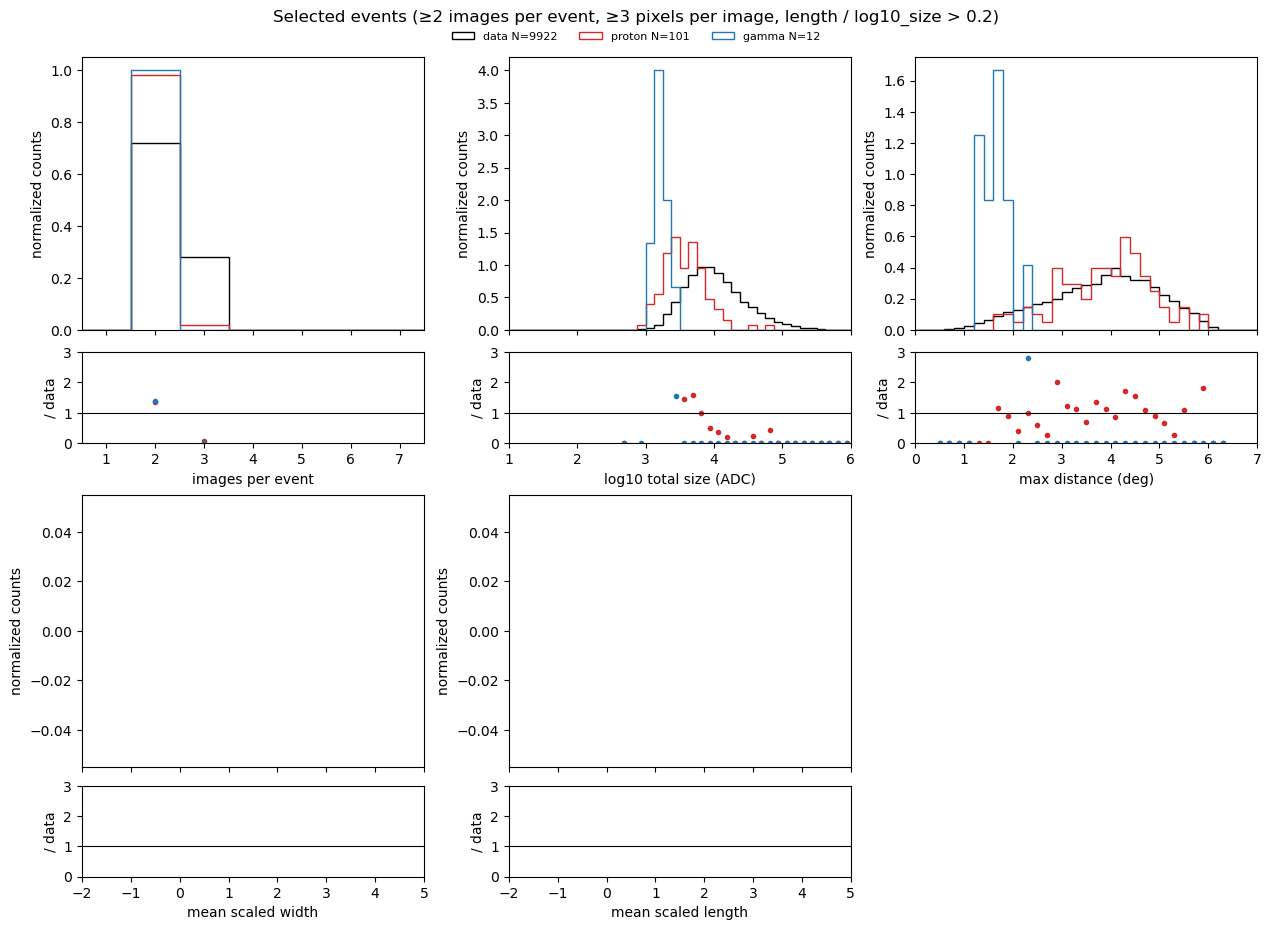

In [ ]:
plot_hists(events, EVENT_PARAMS, f"Selected events ({SELECTED})", n_cols=3)

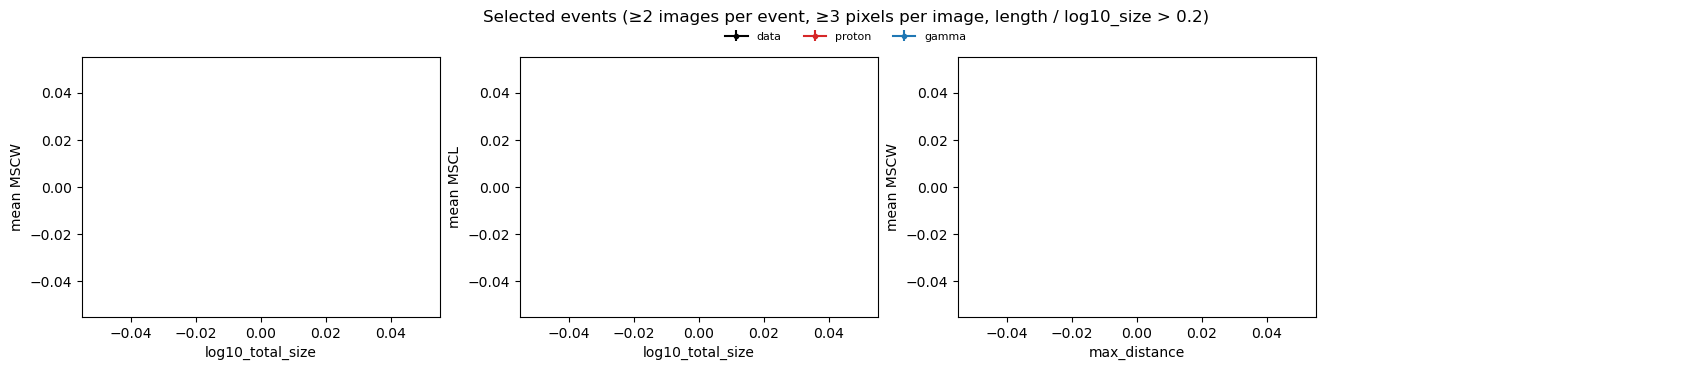

In [ ]:
plot_profiles(events, [
    ("log10_total_size", "MSCW", np.linspace(2.5, 5.5, 13)),
    ("log10_total_size", "MSCL", np.linspace(2.5, 5.5, 13)),
    ("max_distance", "MSCW", np.linspace(0, 5, 11)),
], f"Selected events ({SELECTED})")

In [ ]:
# the fraction of each sample a gamma/hadron cut keeps (e.g. from gamma_hadron.ipynb), as a pandas query on the events
SELECTION = "MSCW < 0.5"
pd.DataFrame({label: {"events": len(e), "kept": e.query(SELECTION).weight.sum() / e.weight.sum()} for label, e in events.items()}).T

,events,kept
data,9922.0,0.0
proton,101.0,0.0
gamma,12.0,0.0


# Random events
`N_EVENTS` random selected events of each sample: each image, then every image's Hillas ellipse on one camera plane, with
the reconstructed direction (`heap.reconstruction.reconstruct_directions()`) and the source position (data) or the true
direction (sims). Rerun for others.

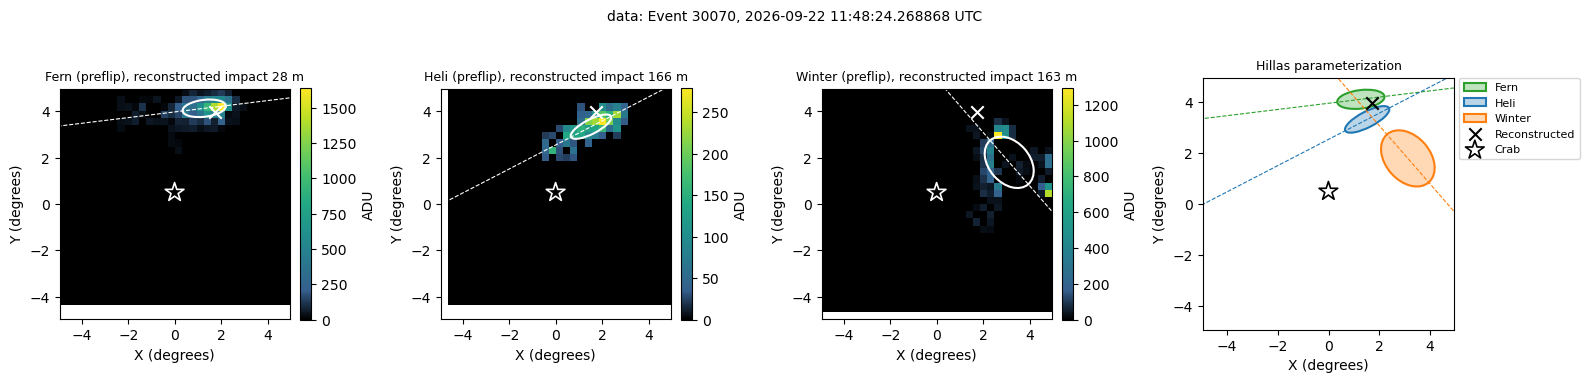

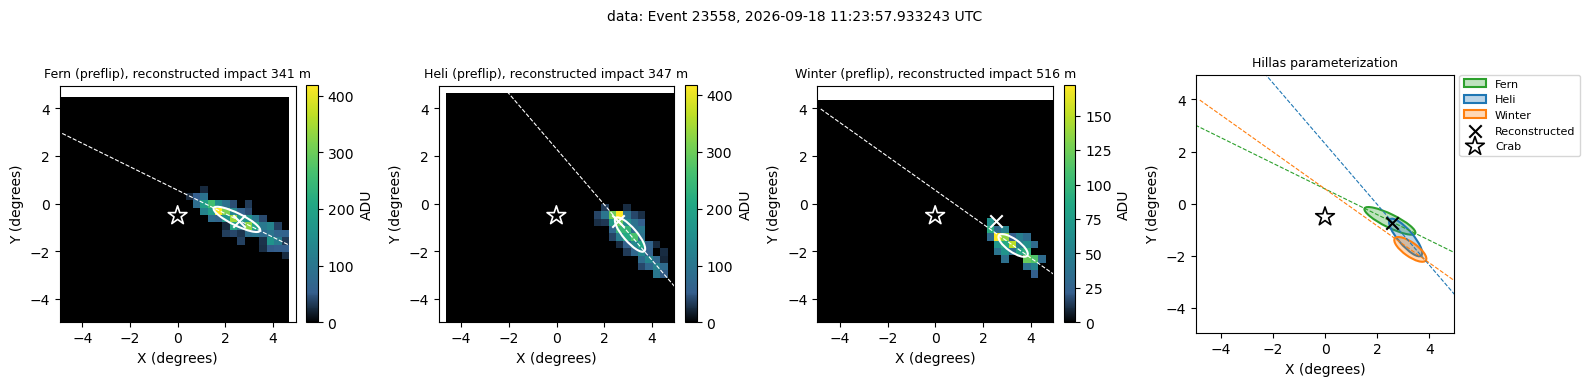

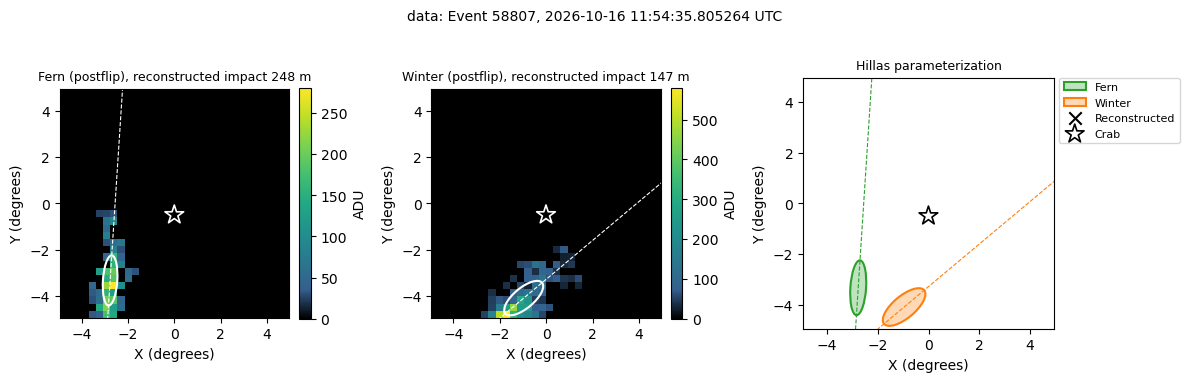

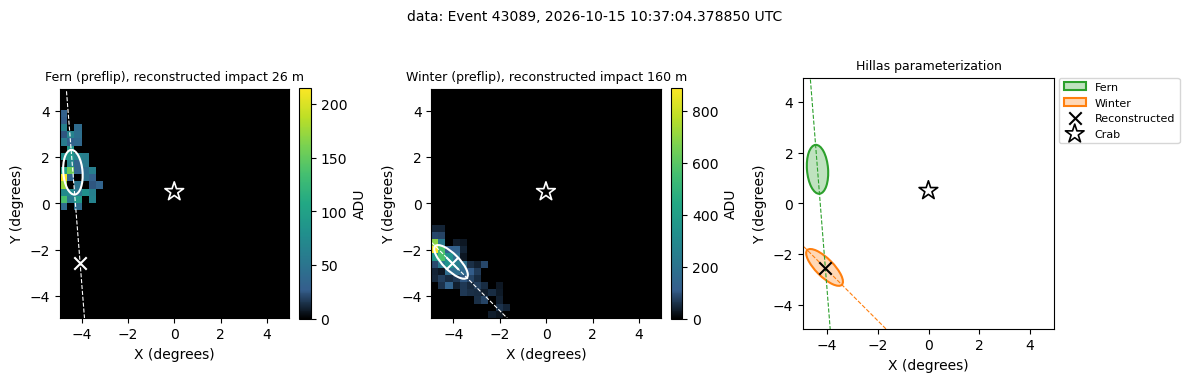

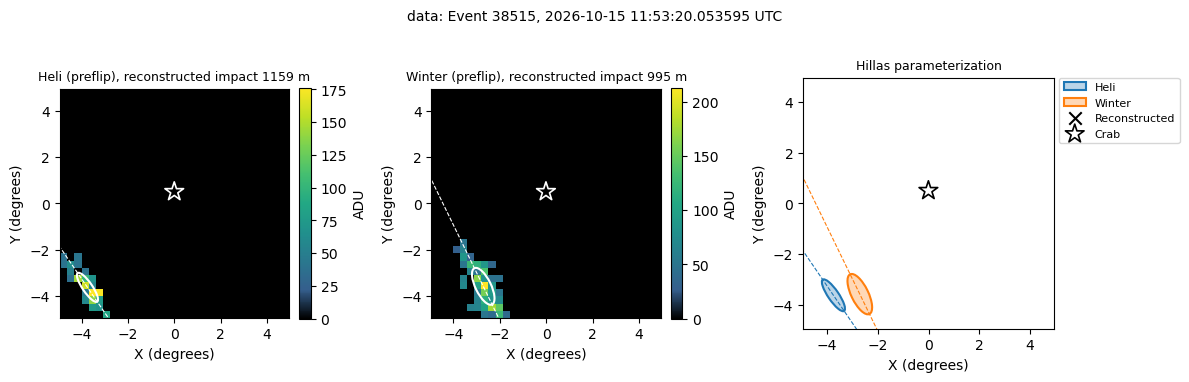

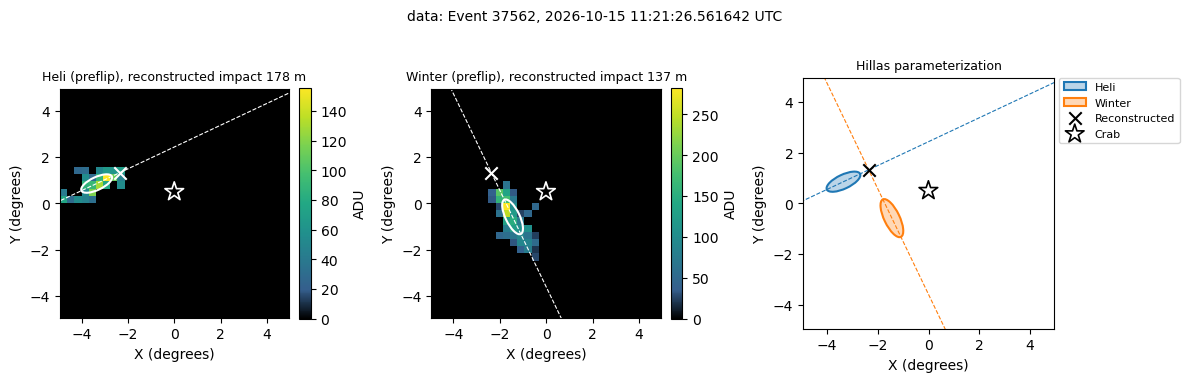

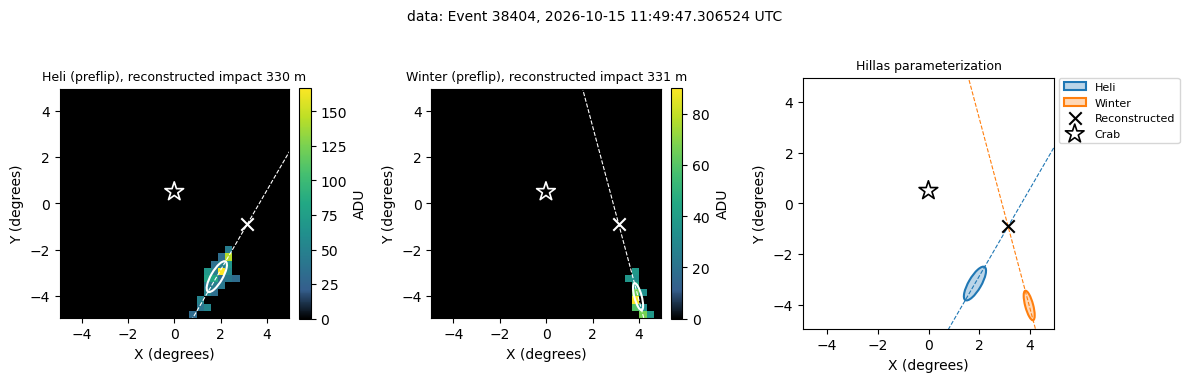

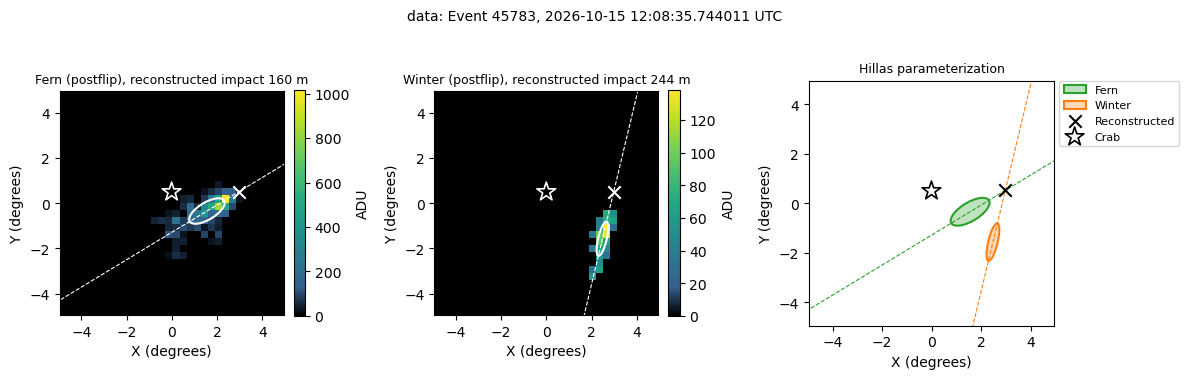

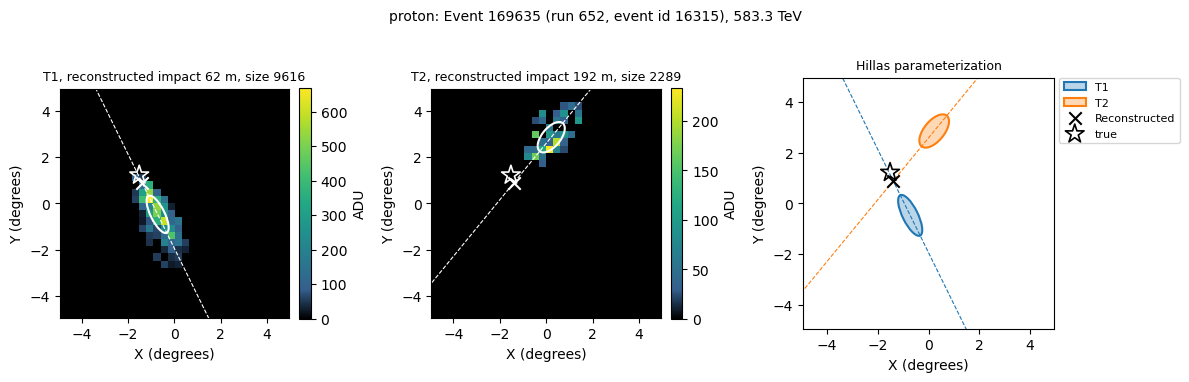

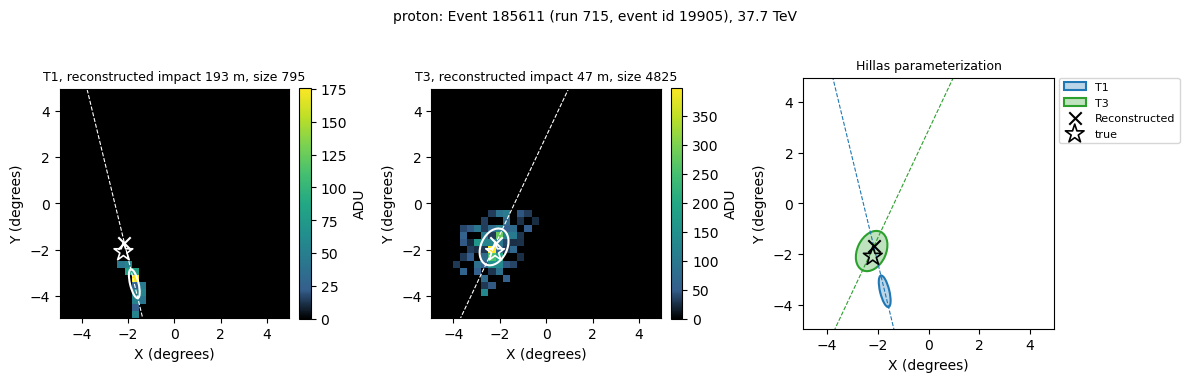

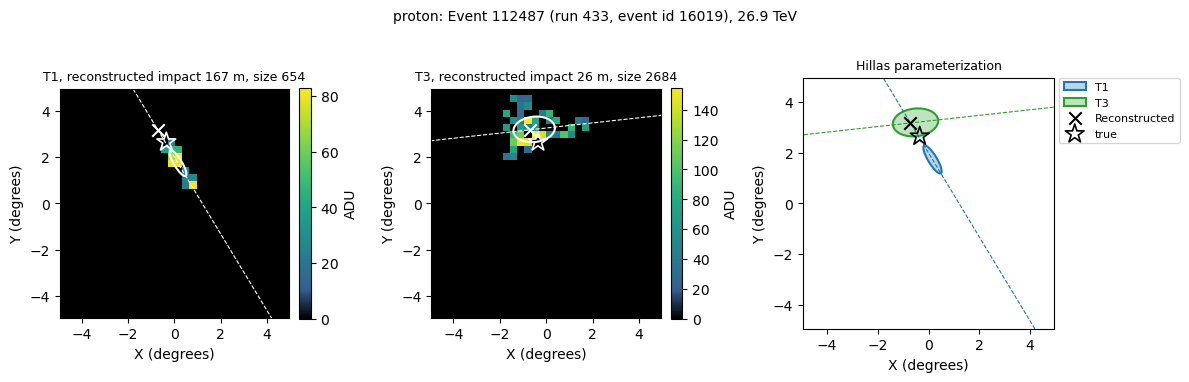

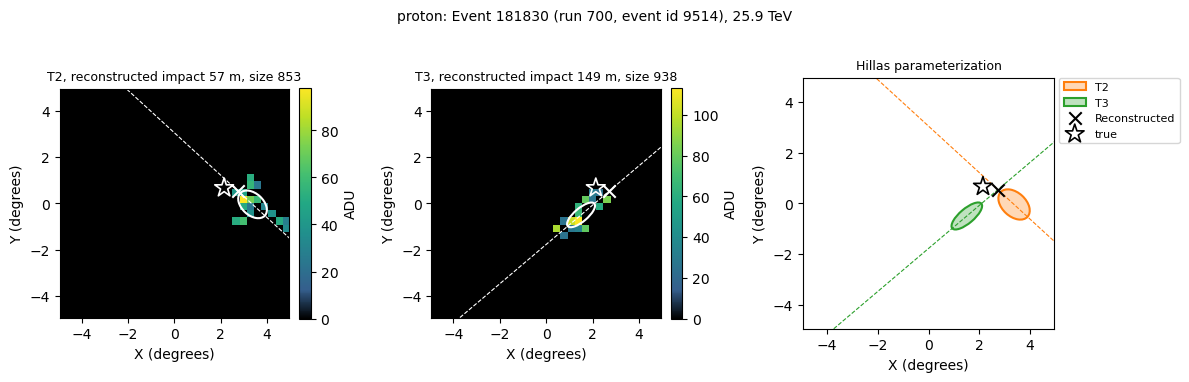

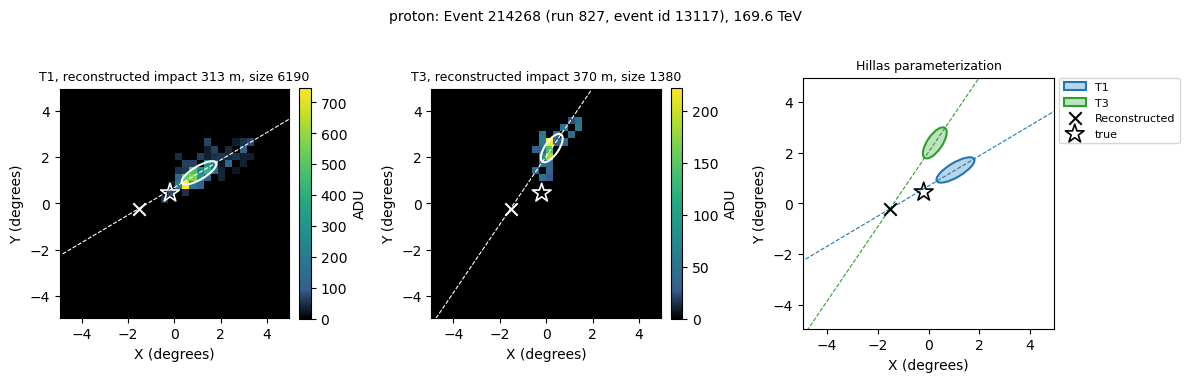

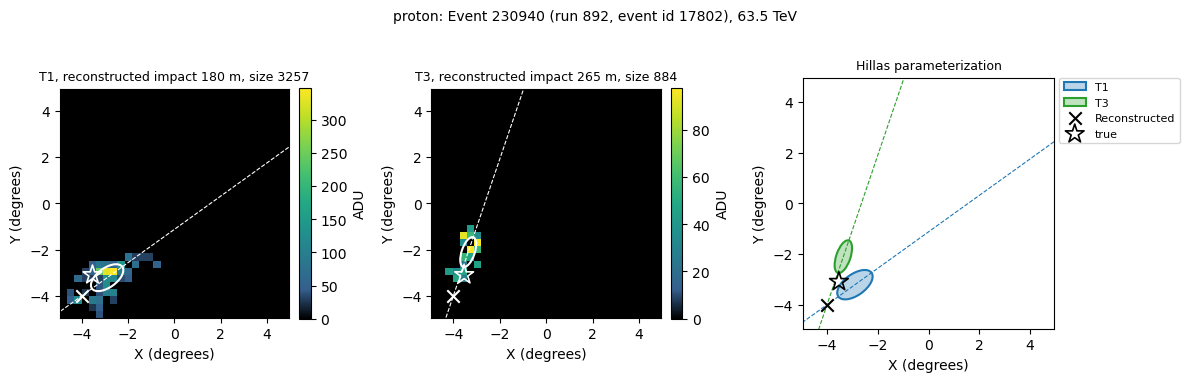

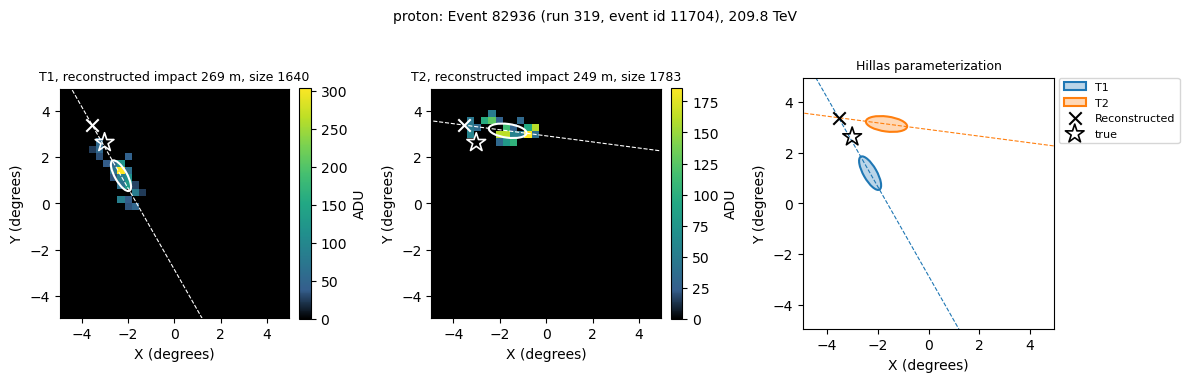

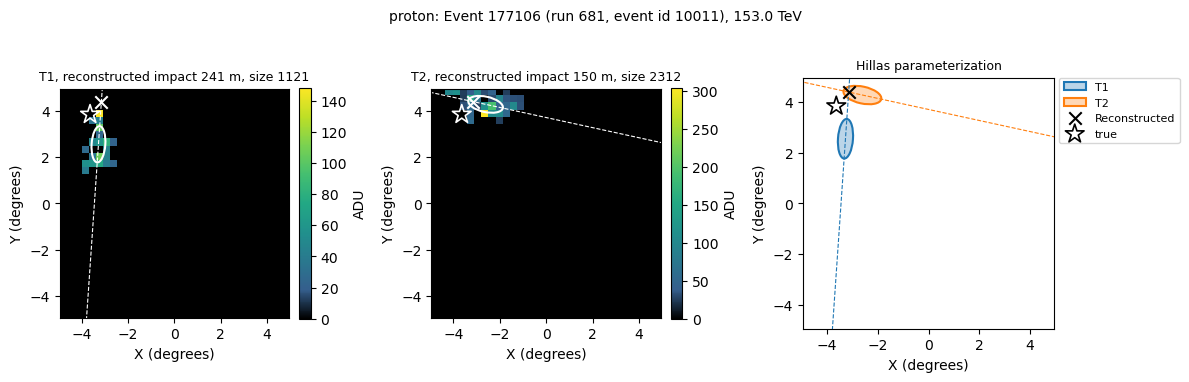

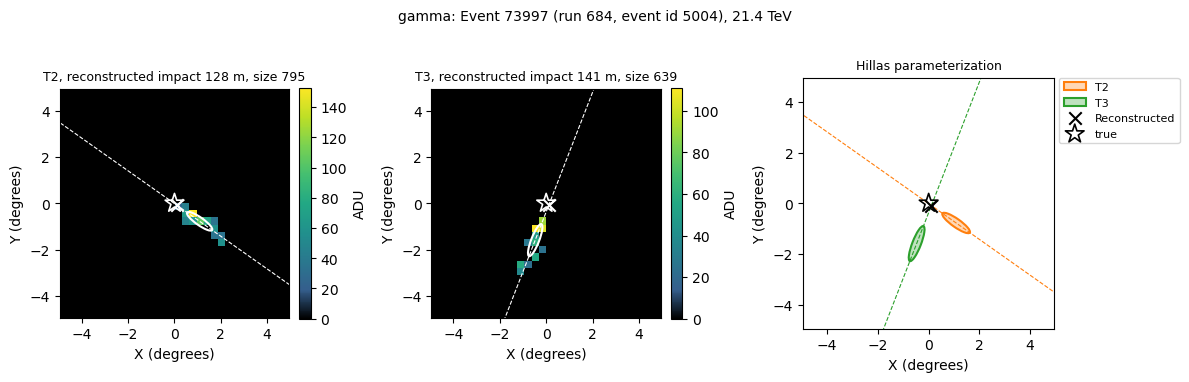

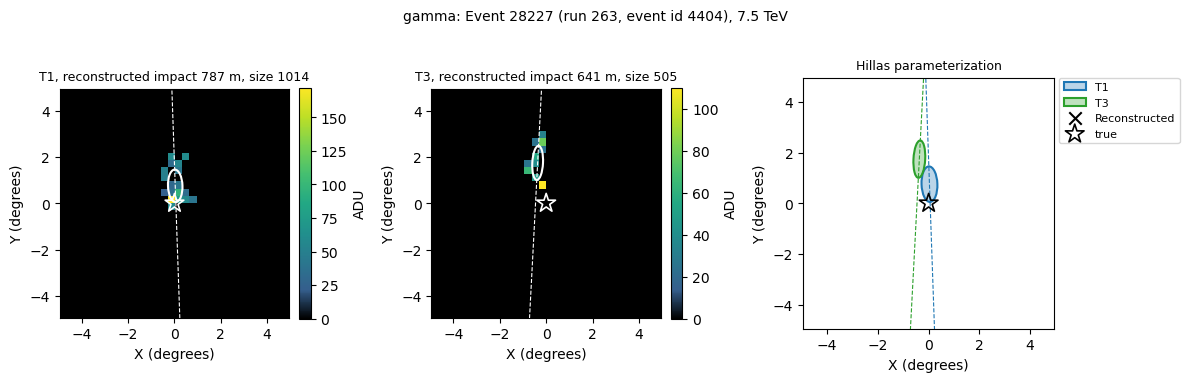

In [84]:
N_EVENTS = 8 # per sample
TEL_COLORS = {name: f"C{i}" for i, name in enumerate(TELESCOPES)} # each telescope's ellipse in the combined panel

rng = np.random.default_rng()
for label, array in arrays.items():
    for e in rng.choice(array.Event.unique(), size=min(N_EVENTS, array.Event.nunique()), replace=False):
        event = array[array.Event == e]
        direction = reconstruct_directions(event).iloc[0]
        if label == "data":
            fig = ev.plot_event(
                event, direction, OUTPUT_DIR, SOURCE, source_position=SOURCES.get(SOURCE), pointings=pointings,
                colors=TEL_COLORS, rotate_postflip=ROTATE_POSTFLIP,
            )
        else:
            # the sims' cleaned images are filed under their sim_telarray ids
            fig = ps.plot_event(
                event.assign(Telescope=event.Telescope.map(SIM_TELESCOPES)), direction,
                showers[label].set_index("Event").loc[e], ps.processed_path(sim_cfgs[label]),
                sim_cfgs[label]["production"]["name"], colors={SIM_TELESCOPES[name]: c for name, c in TEL_COLORS.items()},
            )
        fig.suptitle(f"{label}: {fig.get_suptitle()}", fontsize=10)
        plt.show()